# Fitting one dynamic scene with the test-time solver

This notebook reconstructs one dynamic scene (DyCheck *handwavy*: a waving hand, 32 input frames of a hand-held phone video) and renders
held-out views with their uncertainty. "Fitting" here is the **test-time solve**: one forward pass in which every TTS
layer writes all input tokens into a single fast weight in closed form. No gradient step and no per-scene optimisation is involved.

1. load the model and the scene
2. solve: the state of every TTS layer, its size, and its independence of the input order
3. render held-out views: RGB, error, and the predicted uncertainty (epistemic + aleatoric)
4. how well the uncertainty ranks the error (Pearson, sparsification)
5. more input views → better renderings
6. a novel space-time path: time frozen while the camera moves

In [1]:
import os, sys, time, json
import numpy as np, torch, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from tts4d.inference import load_model, load_scene, inputs_of, encode, render_views, psnr, degrid, rank_match, log_turbo
torch.backends.cuda.matmul.allow_tf32 = True
dev = "cuda"
WEIGHTS = os.environ.get("TTS4D_WEIGHTS", "../weights/tts4d.pth")      # the weights are released with the code
model = load_model(WEIGHTS, "../configs/tts4d.json", dev)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters, {len(model.blocks)} layers")

313.0 M parameters, 24 layers


## 1. The scene
Input frames, cameras in the model frame (first input camera = identity), times in seconds.

32 input views, 12 held-out views, 360x480, inputs span 3.3 s


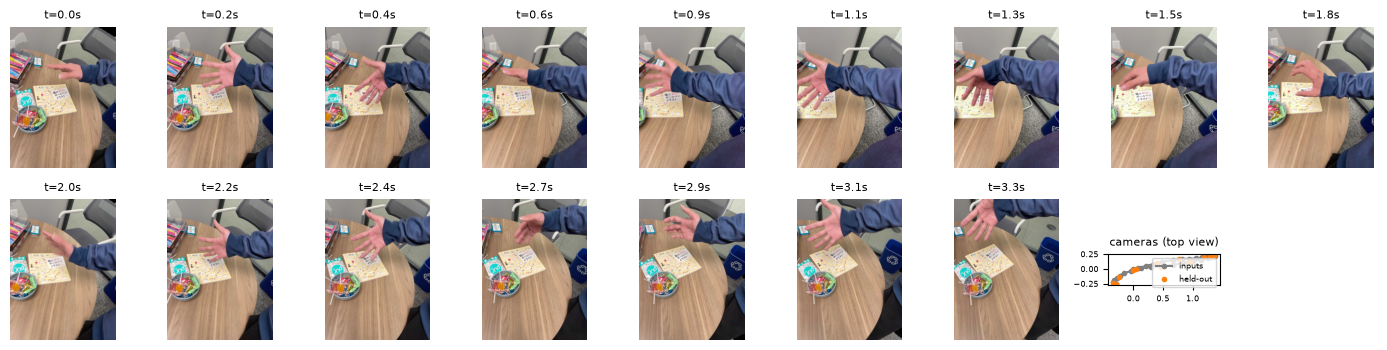

In [2]:
sc = load_scene("../data/dycheck_handwavy.npz")
V, _, H, W = sc["inp_image"].shape
print(f"{V} input views, {len(sc['tgt_c2w'])} held-out views, {W}x{H}, inputs span {sc['inp_time'].max():.1f} s")
fig, ax = plt.subplots(2, 9, figsize=(14, 3.6))
for a, j in zip(ax.ravel()[:16], np.linspace(0, V - 1, 16).round().astype(int)):
    a.imshow(sc["inp_image"][j].transpose(1, 2, 0)); a.set_title(f"t={sc['inp_time'][j]:.1f}s", fontsize=8); a.axis("off")
a = ax.ravel()[16]; ax.ravel()[17].axis("off")
c = sc["inp_c2w"][:, :3, 3]; ct = sc["tgt_c2w"][:, :3, 3]
a.plot(c[:, 0], c[:, 2], ".-", color="0.5", label="inputs"); a.plot(ct[:, 0], ct[:, 2], "o", color="tab:orange", ms=3, label="held-out")
a.set_title("cameras (top view)", fontsize=8); a.legend(fontsize=6); a.set_aspect("equal"); a.tick_params(labelsize=6)
plt.tight_layout(); plt.show()

## 2. The test-time solve
`encode` runs the 32 input views through the network. Every TTS layer accumulates five sufficient statistics of its input
tokens, centres and scales them, and solves for its fast weight with one Cholesky factorisation. Each layer's state has a
**fixed size**: the same with 8 views or 1000.

In [3]:
inp = inputs_of(sc, dev)
torch.cuda.synchronize(); t0 = time.time()
memory = encode(model, inp)
torch.cuda.synchronize(); t_solve = time.time() - t0
n_tok = V * (H // 8) * (W // 8)
st = memory["states"][0]
print(f"solve: {t_solve:.2f} s for {n_tok} input tokens")
print(f"state of one TTS layer: {st.numel() / 1e6:.2f} M numbers (W: {tuple(st.W.shape[1:])}, L^-1: {tuple(st.L_inv.shape[1:])}),"
      f" independent of the number of tokens")
print("ridge lambda per layer:", np.round([float(s.lam.flatten()[0]) for s in memory["states"]], 3))

solve: 4.22 s for 86400 input tokens
state of one TTS layer: 3.54 M numbers (W: (1, 1536, 768), L^-1: (1, 1536, 1536)), independent of the number of tokens
ridge lambda per layer: [8.8010e+00 9.0570e+00 6.5960e+00 8.9580e+00 9.1360e+00 6.8320e+00
 6.9470e+00 4.3350e+00 6.5130e+00 1.4910e+00 2.2500e+00 1.9400e-01
 1.9000e-02 4.1000e-02 1.5000e-02 8.0000e-03 1.0920e+01 8.0000e-03
 9.6470e+00 8.9020e+00 4.0000e-03 4.9870e+00 8.2970e+00 1.1051e+01]


The solve only adds up sums over tokens, so its result does not depend on the order of the input views.
We shuffle the 32 views, solve again, and compare the renderings (in float32 here, so that rounding does not blur the comparison).

In [4]:
tgt = (sc["tgt_c2w"], sc["tgt_K"], sc["tgt_time"])
perm = np.random.RandomState(0).permutation(V)
o32 = render_views(model, encode(model, inp, amp=False), *tgt, dev, amp=False)
o32_perm = render_views(model, encode(model, inputs_of(sc, dev, perm), amp=False), *tgt, dev, amp=False)
d = np.abs(o32["rgb"] - o32_perm["rgb"])
print(f"shuffled input order: max |difference| = {d.max():.1e} (images in [0, 1]), PSNR between the two = "
      f"{np.mean([psnr(a, b) for a, b in zip(o32['rgb'], o32_perm['rgb'])]):.1f} dB")
out = render_views(model, memory, *tgt, dev)          # bfloat16 autocast, as in all our experiments

shuffled input order: max |difference| = 1.9e-02 (images in [0, 1]), PSNR between the two = 74.2 dB


## 3. Held-out views and their uncertainty
Columns: ground truth, our rendering, absolute error, and the predicted standard deviation `exp(U/2)`. The deviation
is shown **rank-matched** to the error (same colour scale, log turbo), so the two maps can be compared by their ranking.
The last two columns split the uncertainty into its epistemic part (from the TTS layers' posterior variance) and its
aleatoric part (learned residual).

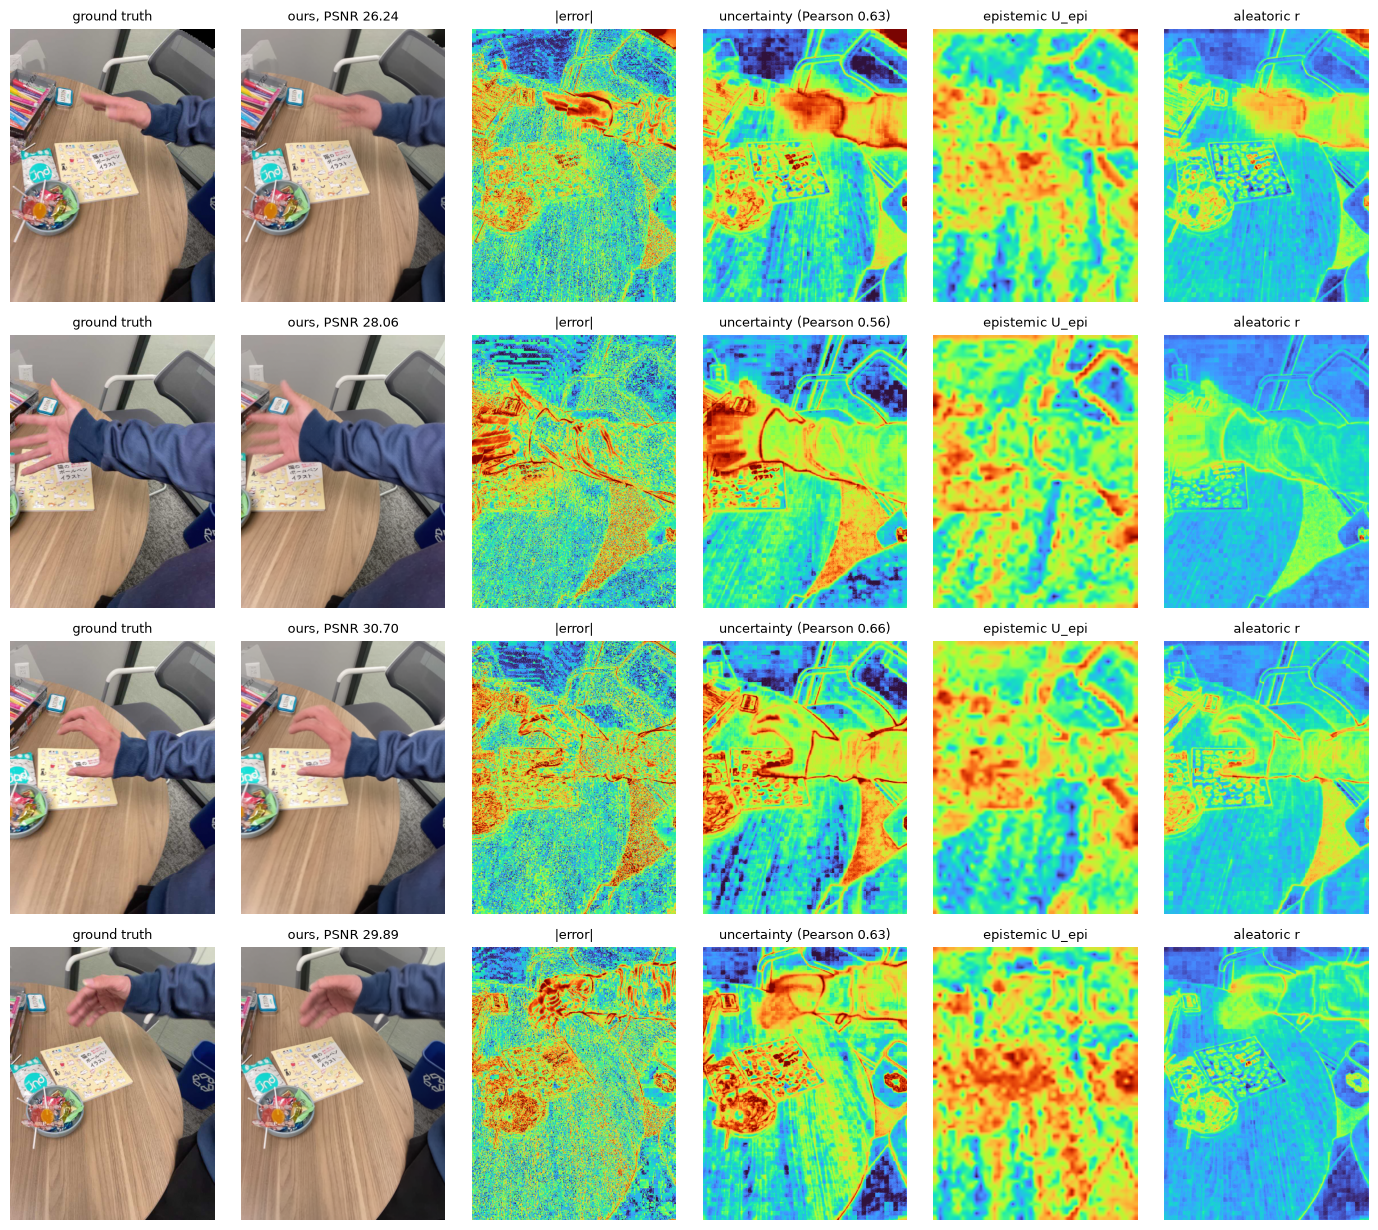

mean PSNR over the 12 held-out views: 28.75 dB


In [5]:
gt = sc["tgt_image"].transpose(0, 2, 3, 1) / 255.0
err = np.abs(out["rgb"] - gt).mean(-1)
show = [0, 3, 6, 9]
fig, ax = plt.subplots(len(show), 6, figsize=(14, 3.1 * len(show)))
for r, i in enumerate(show):
    e_col, (lo, hi) = log_turbo(err[i])
    u_col, _ = log_turbo(rank_match(out["std"][i], err[i]), lo, hi)
    pear = np.corrcoef(out["std"][i].ravel(), err[i].ravel())[0, 1]
    cells = [(gt[i], "ground truth"), (out["rgb"][i], f"ours, PSNR {psnr(out['rgb'][i], gt[i]):.2f}"), (e_col, "|error|"),
             (u_col, f"uncertainty (Pearson {pear:.2f})"), (out["log_var_epi"][i], "epistemic U_epi"), (out["log_var_alea"][i], "aleatoric r")]
    for a, (im, t) in zip(ax[r], cells):
        a.imshow(im, cmap="turbo" if im.ndim == 2 else None); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()
print(f"mean PSNR over the {len(gt)} held-out views: {np.mean([psnr(a, b) for a, b in zip(out['rgb'], gt)]):.2f} dB")

## 4. Does the uncertainty rank the error?
Pearson correlation between the predicted deviation and the per-pixel L1 error, and the sparsification curve: remove
the most uncertain pixels first and track the mean error of the rest. The oracle removes the pixels with the largest
error first; the area between the two curves (AUSE) is 0 for a perfect ranking.

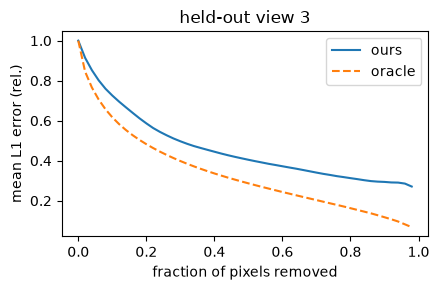

Pearson(std, L1) = 0.618,  AUSE (L1) = 0.136  (means over 12 held-out views)


In [6]:
def sparsification(u, e, steps=50):
    o_u, o_e = np.argsort(-u.ravel()), np.argsort(-e.ravel())
    ev = e.ravel(); n = ev.size
    fr = np.linspace(0, 0.98, steps)
    cu = [ev[o_u[int(f * n):]].mean() for f in fr]; ce = [ev[o_e[int(f * n):]].mean() for f in fr]
    return fr, np.array(cu) / cu[0], np.array(ce) / ce[0]
P, A = [], []
for i in range(len(gt)):
    fr, cu, ce = sparsification(out["std"][i], err[i])
    A.append((getattr(np, "trapezoid", None) or np.trapz)(cu - ce, fr)); P.append(np.corrcoef(out["std"][i].ravel(), err[i].ravel())[0, 1])
fr, cu, ce = sparsification(out["std"][3], err[3])
plt.figure(figsize=(4.5, 3)); plt.plot(fr, cu, label="ours"); plt.plot(fr, ce, "--", label="oracle")
plt.xlabel("fraction of pixels removed"); plt.ylabel("mean L1 error (rel.)"); plt.legend(); plt.title("held-out view 3"); plt.tight_layout(); plt.show()
print(f"Pearson(std, L1) = {np.mean(P):.3f},  AUSE (L1) = {np.mean(A):.3f}  (means over {len(gt)} held-out views)")

## 5. More input views, better renderings
The same held-out views from 8, 16 and 32 input views, spread uniformly over the clip.

 8 input views: PSNR 24.22 dB, mean predicted std 0.0486


16 input views: PSNR 27.15 dB, mean predicted std 0.0326


32 input views: PSNR 28.75 dB, mean predicted std 0.0254


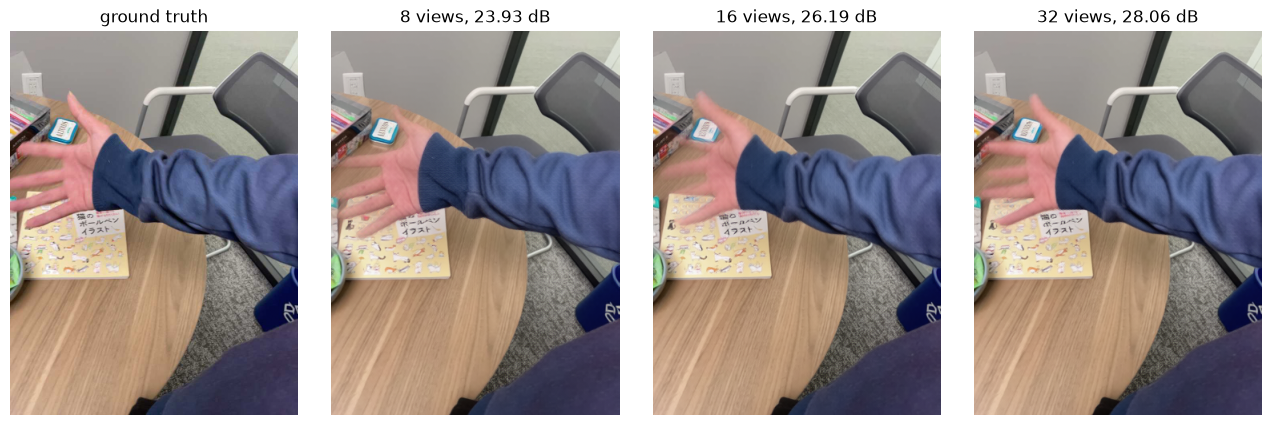

In [7]:
res = {}
for n in (8, 16, 32):
    idx = np.linspace(0, V - 1, n).round().astype(int)
    o = render_views(model, encode(model, inputs_of(sc, dev, idx)), *tgt, dev)
    res[n] = (o, np.mean([psnr(a, b) for a, b in zip(o["rgb"], gt)]))
    print(f"{n:2d} input views: PSNR {res[n][1]:.2f} dB, mean predicted std {o['std'].mean():.4f}")
fig, ax = plt.subplots(1, 4, figsize=(13, 4.2))
ax[0].imshow(gt[3]); ax[0].set_title("ground truth"); ax[0].axis("off")
for a, n in zip(ax[1:], (8, 16, 32)):
    a.imshow(res[n][0]["rgb"][3]); a.set_title(f"{n} views, {psnr(res[n][0]['rgb'][3], gt[3]):.2f} dB"); a.axis("off")
plt.tight_layout(); plt.show()

## 6. A novel space-time path
One solve, many reads: time is frozen at the middle of the clip while the camera travels along the whole input trajectory
(interpolated), i.e. viewpoints that were never captured at that moment. The uncertainty grows where the view leaves
what the inputs observed. We also apply the training-free grid removal of the supplement.

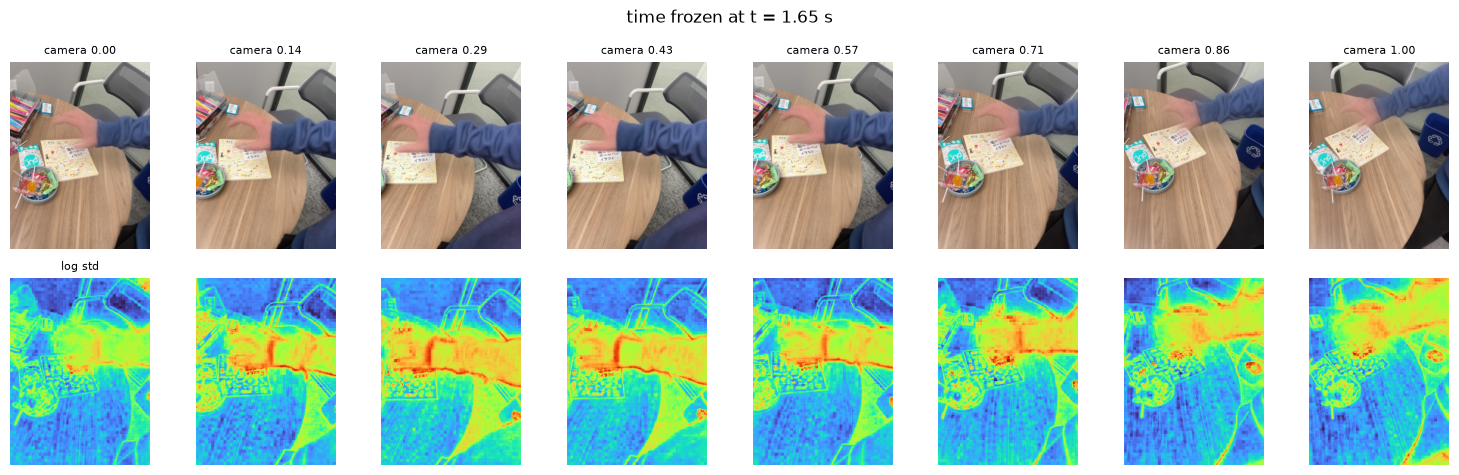

In [8]:
from scipy.spatial.transform import Rotation, Slerp
c2w = sc["inp_c2w"]; key = np.linspace(0, 1, V)
slerp = Slerp(key, Rotation.from_matrix(c2w[:, :3, :3]))
s = np.linspace(0, 1, 8)
path = np.tile(np.eye(4), (len(s), 1, 1)); path[:, :3, :3] = slerp(s).as_matrix()
for k in range(3): path[:, k, 3] = np.interp(s, key, c2w[:, k, 3])
t_mid = float(np.median(sc["inp_time"]))
o = render_views(model, memory, path, np.repeat(sc["inp_K"][:1], len(s), 0), np.full(len(s), t_mid), dev)
rgb = degrid(o["rgb"])
fig, ax = plt.subplots(2, len(s), figsize=(15, 4.8))
for j in range(len(s)):
    ax[0, j].imshow(rgb[j]); ax[0, j].axis("off"); ax[0, j].set_title(f"camera {s[j]:.2f}", fontsize=8)
    ax[1, j].imshow(np.log(o["std"][j]), cmap="turbo"); ax[1, j].axis("off")
ax[0, 0].set_ylabel("rendering"); ax[1, 0].set_title("log std", fontsize=8)
plt.suptitle(f"time frozen at t = {t_mid:.2f} s"); plt.tight_layout(); plt.show()